# 03 · Validación, líneas base y candidatos

Este notebook fija **cómo se compara** cualquier modelo del proyecto y aplica esa comparación a las
líneas base y a las cinco familias de candidatos, todas con sus hiperparámetros por defecto:

1. Esquema de validación cruzada temporal (§1) y métricas (§2).
2. Contrato de registro en MLflow: qué guarda cada corrida (§3).
3. Tres líneas base: ingenua y las dos reglas de negocio del PSet 1 (§4).
4. Cinco candidatos: Ridge, bosque aleatorio, gradient boosting, red neuronal y Chronos-Bolt (§5).
5. Resultados, diagnóstico de sobreajuste y elección de los 3 modelos para el tuning (§6).

**El conjunto de prueba (31/07–15/08/2017) no se usa aquí.** Todo se decide con la validación
cruzada sobre el entrenamiento.

In [1]:
import logging
import os
import subprocess
import sys
import time
import warnings

sys.path.insert(0, '..')
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
os.environ.setdefault('MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR', 'false')
os.environ.setdefault('TQDM_DISABLE', '1')          # barras de progreso de Hugging Face
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from mlflow.models import infer_signature
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_validate
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

from src.datos import cargar_muestra
from src.pipeline import (CHRONOS, HORIZONTE, INICIO_PRUEBA, METRICAS, OBJETIVO, SERIE,
                          ChronosBolt, ReglaSemanal, construir_features, dividir, en_escala_log,
                          pliegues, preparacion)

logging.getLogger('mlflow').setLevel(logging.ERROR)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

FIGURAS = '../docs/figuras'
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#b8b7b0'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b8b7b0',
    'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})


def comprobar(numero, condicion):
    if condicion:
        print(f"Comprobación {numero}: OK")
    else:
        print(f"Comprobación {numero}: revisa")


ventas, meta = cargar_muestra()
datos = construir_features(ventas)
# Las claves (tienda, producto, fecha) viajan en X: la preparación las descarta, pero las
# reglas de negocio y Chronos las necesitan para saber qué serie y qué día pronosticar.
X_ent, X_prueba, y_ent, y_prueba = dividir(datos, columnas_extra=SERIE + ['DATE'])
print('Huella de la muestra:', meta['sha256'])
print(f'Entrenamiento: {X_ent.shape[0]:,} filas, {X_ent["DATE"].min():%d/%m/%Y} a {X_ent["DATE"].max():%d/%m/%Y}')
print(f'Prueba (no se usa en este notebook): {X_prueba.shape[0]:,} filas')

C:\Users\lroja\MSDS\Data Science\Pset3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Huella de la muestra: 4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee2a4deb035538e899cc
Entrenamiento: 593,174 filas, 13/09/2016 a 30/07/2017
Prueba (no se usa en este notebook): 32,000 filas


## 1. Esquema de validación: temporal, por fechas

**Elección: `TimeSeriesSplit` sobre las fechas, 5 pliegues de 16 días, ventana creciente**
(`pliegues()` en `src/pipeline.py`).

| Alternativa | ¿Sirve aquí? |
|---|---|
| Aleatorio (`KFold`, `train_test_split`) | No. Mezcla días: el modelo entrenaría con el 20/07 para validar el 19/07, y las ventas de días vecinos están muy correlacionadas (EDA §5.2). La métrica saldría optimista. |
| Por grupo (`GroupKFold` por serie) | No es la pregunta del negocio. En producción se pronostica el **futuro de las mismas series**, no series nuevas. |
| Estratificado | Es para clasificación. |
| **Temporal** | Sí. Cada pliegue entrena con todo lo anterior a un corte y valida los 16 días siguientes, igual que el uso real. |

Dos detalles de diseño:

- **El corte se hace sobre las fechas, no sobre las filas.** `TimeSeriesSplit` aplicado directo a las
  filas podría partir un mismo día entre entrenamiento y validación. Se aplica a la lista de fechas
  únicas y luego se traduce a filas.
- **Ventanas de 16 días = el horizonte.** Cada pliegue mide justamente el error de pronosticar
  *c+1, …, c+16*. No hace falta un hueco (`gap`) entre entrenamiento y validación: las features
  usan solo datos de *t−16* o antes (notebook 02), así que ningún dato del pliegue de validación
  entra en sus propias features.

In [2]:
esquema_temporal = pliegues(X_ent)
fechas = X_ent['DATE']
tabla_pliegues = pd.DataFrame([{
    'pliegue': i,
    'entrena_desde': fechas.iloc[ent].min().date(),
    'entrena_hasta': fechas.iloc[ent].max().date(),
    'valida_desde': fechas.iloc[val].min().date(),
    'valida_hasta': fechas.iloc[val].max().date(),
    'dias_validacion': fechas.iloc[val].nunique(),
    'filas_entrenamiento': len(ent),
    'filas_validacion': len(val),
} for i, (ent, val) in enumerate(esquema_temporal, start=1)]).set_index('pliegue')
tabla_pliegues

,entrena_desde,entrena_hasta,valida_desde,valida_hasta,dias_validacion,filas_entrenamiento,filas_validacion
pliegue,,,,,,,
1,2016-09-13,2017-05-11,2017-05-12,2017-05-27,16,433436,31788
2,2016-09-13,2017-05-27,2017-05-28,2017-06-12,16,465224,31950
3,2016-09-13,2017-06-12,2017-06-13,2017-06-28,16,497174,32000
4,2016-09-13,2017-06-28,2017-06-29,2017-07-14,16,529174,32000
5,2016-09-13,2017-07-14,2017-07-15,2017-07-30,16,561174,32000


In [3]:
un_dia = pd.Timedelta(days=1)
contiguos = all(pd.Timestamp(f['valida_desde']) == pd.Timestamp(f['entrena_hasta']) + un_dia
                for _, f in tabla_pliegues.iterrows())
comprobar(1, contiguos and (tabla_pliegues['dias_validacion'] == HORIZONTE).all())
# El último pliegue termina el día anterior a la prueba: la prueba nunca entra en la CV.
comprobar(2, pd.Timestamp(tabla_pliegues['valida_hasta'].iloc[-1]) == pd.Timestamp(INICIO_PRUEBA) - un_dia
          and X_ent['DATE'].max() < pd.Timestamp(INICIO_PRUEBA))

Comprobación 1: OK
Comprobación 2: OK


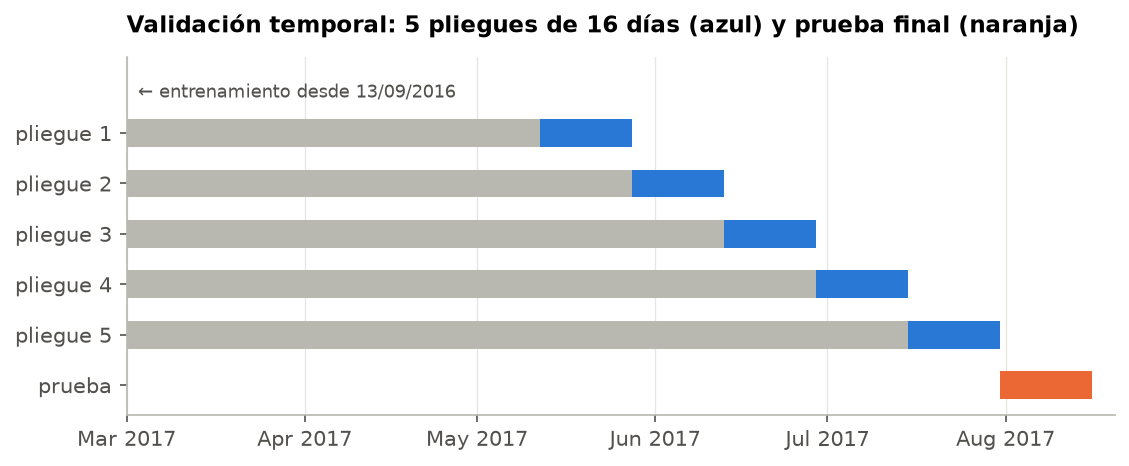

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.1))
for i, f in tabla_pliegues.iterrows():
    inicio_ent = mdates.date2num(pd.Timestamp(f['entrena_desde']))
    inicio_val = mdates.date2num(pd.Timestamp(f['valida_desde']))
    ax.barh(i, inicio_val - inicio_ent, left=inicio_ent, height=0.55, color=GRIS)
    ax.barh(i, HORIZONTE, left=inicio_val, height=0.55, color=AZUL)
ax.barh(6, HORIZONTE, left=mdates.date2num(pd.Timestamp(INICIO_PRUEBA)), height=0.55, color=NARANJA)
ax.set_yticks(range(1, 7), [f'pliegue {i}' for i in range(1, 6)] + ['prueba'])
ax.set_ylim(6.6, -0.5)  # eje invertido con una fila libre arriba para la nota
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(mdates.date2num(pd.Timestamp('2017-03-01')), mdates.date2num(pd.Timestamp('2017-08-20')))
ax.text(mdates.date2num(pd.Timestamp('2017-03-03')), 0.2, '← entrenamiento desde 13/09/2016',
        fontsize=8.5, color=TINTA_2, va='center')
ax.set_title('Validación temporal: 5 pliegues de 16 días (azul) y prueba final (naranja)', pad=12)
ax.grid(axis='y', visible=False)
fig.savefig(f'{FIGURAS}/validacion_pliegues.png')
plt.show()

## 2. Métricas

| Métrica | Uso |
|---|---|
| **RMSLE** (= NWRMSLE del PSet 1, todos los productos son perecederos) | **Métrica técnica.** Ordena los candidatos y guía el tuning. Es la misma para todos los modelos. El ganador final se elige por la métrica de negocio (notebook 05). |
| MAE (unidades) | Complemento del PSet 1: error en unidades, dominado por las series grandes. |
| Sesgo (unidades, predicho − real) | Complemento: un modelo que subestima de forma sistemática genera faltantes. |

**Metas.** Técnica: RMSLE al menos 5 % menor que la mejor línea base en la validación cruzada (se evalúa en este notebook).
Negocio: al menos 5 % de ahorro de costo en el escenario Co:Cu 1:3 frente a la media de 28 días con stock de seguridad aditivo,
en la validación y en la prueba (notebook 05).

Para la métrica técnica, cada modelo de aprendizaje se entrena sobre `log1p(y)`
(`en_escala_log()`), porque minimizar el error cuadrático en esa escala equivale a minimizar el
RMSLE (hallazgo 1 del EDA: cola larga y escala muy distinta entre series).

**Métrica de negocio.** La regla de reposición diseñada para este PSet (pedido = pronóstico + stock de seguridad,
con tasa de merma, tasa de cobertura y costo ponderado faltantes:sobrantes) necesita la distribución
de los errores de cada modelo para fijar el stock de seguridad. Se calcula en el notebook 05, donde
decide el modelo ganador. Aquí el sesgo anticipa el lado del error.

## 3. Registro en MLflow

Cada corrida guarda lo mismo, mediante la función `evaluar()`:

| Qué | Cómo se registra |
|---|---|
| Parámetros | Todos los hiperparámetros del modelo (`get_params()`) y `semilla` |
| Datos | `tabla_origen`, `fecha_corte_snapshot`, `huella_datos` (SHA-256 de la muestra), `n_series`, `filas_entrenamiento`, `esquema_cv` |
| Métricas | `rmsle_entrenamiento`, `rmsle_cv` y `rmsle_cv_std`, `brecha`, `mae_cv`, `sesgo_cv`, `segundos` (ajuste final), `segundos_cv`, y el RMSLE de cada pliegue (`rmsle_cv_pliegue`, con `step` = pliegue) |
| Tags | `fase` (baseline, candidato, …), `familia`, `git_commit`, `git_cambios_sin_commit` |
| Artefacto | El pipeline completo (preparación + modelo) ajustado con todo el entrenamiento, con firma, ejemplo de entrada y el código de `src/` (`code_paths`) para poder cargarlo en otra sesión |

**Formato del artefacto: `skops`**, el que MLflow recomienda. A diferencia de pickle, `skops` no
ejecuta código arbitrario al cargar un modelo, y solo acepta los tipos declarados como confiables
(`CONFIABLES`): las clases propias de `src/pipeline.py`, `numpy.dtype` y dos piezas internas de
scikit-learn (el predictor de `HistGradientBoosting` y el optimizador Adam de la red).

**Métrica de entrenamiento y brecha.** El error de entrenamiento es el promedio, en los 5 pliegues,
del error sobre las filas con que se entrenó cada pliegue. Así, `brecha = rmsle_cv − rmsle_entrenamiento`
compara cada pliegue consigo mismo.

In [5]:
load_dotenv('../.env')
EXPERIMENTO = os.environ.get('MLFLOW_EXPERIMENT_NAME', 'favorita-perecederos')
mlflow.set_experiment(EXPERIMENTO)
SEMILLA = 42


def git(*argumentos):
    try:
        return subprocess.run(['git', *argumentos], capture_output=True, text=True, check=True,
                              cwd='..').stdout.strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None


GIT_COMMIT = git('rev-parse', 'HEAD') or 'sin-commit'
GIT_SUCIO = 'si' if git('status', '--porcelain', '--', 'src', 'notebooks') else 'no'

DATOS = {
    'tabla_origen': meta['tabla_origen'],
    'fecha_corte_snapshot': meta['fecha_corte_snapshot'],
    'huella_datos': meta['sha256'],
    'n_series': meta['n_series'],
    'filas_entrenamiento': len(X_ent),
    'esquema_cv': f'TimeSeriesSplit por fecha, {len(esquema_temporal)} pliegues de {HORIZONTE} dias',
}
# Ejemplo de entrada para la firma: filas como las que llegan al pronosticar (fechas posteriores
# al corte). Son features de entrenamiento con la fecha desplazada; no se toca la prueba.
ejemplo = X_ent.tail(5).assign(DATE=lambda d: d['DATE'] + pd.Timedelta(days=HORIZONTE))
# Tipos que skops carga además de los básicos de scikit-learn: las clases propias y dos piezas
# internas de scikit-learn que skops pide confirmar (los archivos los creamos nosotros).
CONFIABLES = ['numpy.dtype', 'src.pipeline.deshacer_log', 'src.pipeline.ReglaSemanal',
              'src.pipeline.ChronosBolt',
              'sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor',
              'sklearn.tree._tree.Tree',
              'sklearn.neural_network._stochastic_optimizers.AdamOptimizer']

print('Tracking:', mlflow.get_tracking_uri(), '| experimento:', EXPERIMENTO)
print('Commit:', GIT_COMMIT, '| cambios sin commit:', GIT_SUCIO)

Tracking: http://127.0.0.1:5050 | experimento: favorita-perecederos
Commit: 6eb6c51201cb139621b48109dc0a600998e62a9c | cambios sin commit: no


In [6]:
resultados = {}


def evaluar(nombre, modelo, familia, fase='candidato', preparar=True, escala_log=True,
            entrenamiento=True, guardar_modelo=True, nota=None):
    """Validación cruzada temporal + ajuste final + registro en MLflow.

    preparar: antepone preparacion() (las reglas y Chronos leen las columnas crudas).
    escala_log: entrena sobre log1p(y) con en_escala_log().
    entrenamiento: calcula el error de entrenamiento (no aplica a modelos que no aprenden de X).
    """
    pasos = [('preparar', preparacion())] if preparar else []
    pasos.append(('modelo', en_escala_log(modelo) if escala_log else modelo))
    pipeline = Pipeline(pasos)

    with mlflow.start_run(run_name=nombre) as corrida:
        mlflow.set_tags({'fase': fase, 'familia': familia, 'git_commit': GIT_COMMIT,
                         'git_cambios_sin_commit': GIT_SUCIO,
                         'escala_objetivo': 'log1p' if escala_log else 'unidades'})
        if nota:
            mlflow.set_tag('nota', nota)
        mlflow.log_params({**modelo.get_params(), **DATOS, 'semilla': SEMILLA})

        inicio = time.perf_counter()
        puntajes = cross_validate(pipeline, X_ent, y_ent, cv=esquema_temporal, scoring=METRICAS,
                                  return_train_score=entrenamiento)
        segundos_cv = time.perf_counter() - inicio
        errores = -puntajes['test_rmsle']
        for paso, error in enumerate(errores, start=1):
            mlflow.log_metric('rmsle_cv_pliegue', error, step=paso)

        metricas = {'rmsle_cv': errores.mean(), 'rmsle_cv_std': errores.std(),
                    'mae_cv': -puntajes['test_mae'].mean(), 'sesgo_cv': puntajes['test_sesgo'].mean(),
                    'segundos_cv': segundos_cv}
        if entrenamiento:
            metricas['rmsle_entrenamiento'] = -puntajes['train_rmsle'].mean()
            metricas['brecha'] = metricas['rmsle_cv'] - metricas['rmsle_entrenamiento']

        inicio = time.perf_counter()
        pipeline.fit(X_ent, y_ent)
        metricas['segundos'] = time.perf_counter() - inicio
        ajustado = pipeline.named_steps['modelo']
        ajustado = getattr(ajustado, 'regressor_', ajustado)
        if getattr(ajustado, 'n_iter_', None) is not None:     # Ridge lo define como None
            metricas['iteraciones'] = int(np.max(ajustado.n_iter_))
        mlflow.log_metrics(metricas)

        if guardar_modelo:
            mlflow.sklearn.log_model(pipeline, name='modelo', input_example=ejemplo,
                                     signature=infer_signature(ejemplo, pipeline.predict(ejemplo)),
                                     code_paths=['../src'], skops_trusted_types=CONFIABLES)
        mlflow.set_tag('modelo_guardado', 'si' if guardar_modelo else 'no')

    params = modelo.get_params()
    resultados[nombre] = {
        'modelo': nombre, 'fase': fase, 'familia': familia,
        'rmsle_entrenamiento': metricas.get('rmsle_entrenamiento', np.nan),
        'rmsle_cv': metricas['rmsle_cv'], 'rmsle_cv_std': metricas['rmsle_cv_std'],
        'brecha': metricas.get('brecha', np.nan),
        'mae_cv': metricas['mae_cv'], 'sesgo_cv': metricas['sesgo_cv'],
        # La red llama learning_rate al tipo de calendario ('constant'); la tasa es learning_rate_init.
        'learning_rate': params.get('learning_rate_init', params.get('learning_rate', np.nan)),
        'segundos': metricas['segundos'], 'segundos_cv': segundos_cv,
        'pliegues': errores, 'run_id': corrida.info.run_id,
    }
    del pipeline
    texto_ent = f"entrenamiento {metricas['rmsle_entrenamiento']:.4f}   " if entrenamiento else ' ' * 23
    print(f"{nombre:18s} {texto_ent}CV {errores.mean():.4f} ± {errores.std():.4f}   "
          f"ajuste {metricas['segundos']:7.1f} s   CV {segundos_cv:7.1f} s")

## 4. Líneas base

| Corrida | Qué predice | Por qué |
|---|---|---|
| `linea base` | `DummyRegressor` (media) sobre `log1p(y)`: una sola cifra para toda fila | Ingenua. En escala log, la media es la constante que minimiza el RMSLE. |
| `regla semanal` | La venta del mismo día de la semana en la última semana antes del corte, repetida en el horizonte | **Regla de negocio principal del PSet 1** (`ReglaSemanal('ultima_semana')`). |
| `media 28 dias` | La media de los últimos 28 días antes del corte | Segunda referencia que el PSet 1 pidió comparar (`ReglaSemanal('media_28')`). |

Las dos reglas usan la historia **hasta el corte** de cada pliegue, igual que un comprador que
repite la semana pasada. Si a una serie le falta el dato, se usa la media de la serie, luego la de su
familia en la tienda y luego la global (respaldo definido en el PSet 1). Las reglas no aprenden de las
filas de entrenamiento: su "error de entrenamiento" no mide ajuste y no se reporta.

In [7]:
evaluar('linea base', DummyRegressor(), 'dummy', fase='baseline')
evaluar('regla semanal', ReglaSemanal('ultima_semana'), 'regla de negocio', fase='baseline',
        preparar=False, escala_log=False, entrenamiento=False)
evaluar('media 28 dias', ReglaSemanal('media_28'), 'regla de negocio', fase='baseline',
        preparar=False, escala_log=False, entrenamiento=False)

🏃 View run linea base at: http://127.0.0.1:5050/#/experiments/3/runs/b9408e7ddb72431dba1225db4084a33d
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
linea base         entrenamiento 1.1637   CV 1.1783 ± 0.0062   ajuste     4.1 s   CV    26.2 s


🏃 View run regla semanal at: http://127.0.0.1:5050/#/experiments/3/runs/9d223f6daa1f48a4bcddcfa776e8a6ae
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
regla semanal                             CV 0.8505 ± 0.0188   ajuste     0.1 s   CV     0.6 s


🏃 View run media 28 dias at: http://127.0.0.1:5050/#/experiments/3/runs/00dc0c037b5841bb9c17fcf0ada0c1a6
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
media 28 dias                             CV 0.7231 ± 0.0216   ajuste     0.1 s   CV     0.6 s


## 5. Candidatos con hiperparámetros por defecto

Mismo `X_ent`, mismos 5 pliegues, misma métrica y misma preparación (`preparacion()`) para las cuatro
familias de scikit-learn. Solo se fija `random_state=42` y, en el bosque, `n_jobs=-1` (usa todos los
núcleos; no cambia el modelo).

| Corrida | Familia | Modelo |
|---|---|---|
| `ridge` | Lineal regularizado | `Ridge()` |
| `bosque aleatorio` | Bagging | `RandomForestRegressor()` (100 árboles sin límite de profundidad) |
| `gradient boosting` | Boosting | `HistGradientBoostingRegressor()` |
| `red neuronal` | Red neuronal | `MLPRegressor()` (una capa de 100 neuronas, Adam) |
| `chronos bolt` | State of the art | Chronos-Bolt *small* (Amazon), modelo fundacional de series de tiempo, sin reentrenar |

**Bosque aleatorio sin artefacto.** Con los valores por defecto, cada árbol crece hasta hojas casi
puras: en una medición previa de este mismo entrenamiento dio ≈ 486 mil nodos por árbol, unos
4 GB para 100 árboles. Se registran sus parámetros y métricas, pero no el modelo (`modelo_guardado = no`):
la corrida se reproduce con los parámetros, la huella de los datos y el commit.

In [8]:
evaluar('ridge', Ridge(), 'lineal regularizado')

🏃 View run ridge at: http://127.0.0.1:5050/#/experiments/3/runs/8e7f1bdc8c8848828c48326883da422a
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
ridge              entrenamiento 0.7003   CV 0.6874 ± 0.0268   ajuste     4.9 s   CV    27.3 s


In [9]:
evaluar('bosque aleatorio', RandomForestRegressor(random_state=SEMILLA, n_jobs=-1), 'bagging',
        guardar_modelo=False, nota='modelo de ~4 GB con valores por defecto: no se guarda el artefacto')

🏃 View run bosque aleatorio at: http://127.0.0.1:5050/#/experiments/3/runs/3a96bcdf830c44b396b680f891d5fcdb
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
bosque aleatorio   entrenamiento 0.2498   CV 0.6795 ± 0.0270   ajuste   968.4 s   CV  4185.6 s


In [10]:
evaluar('gradient boosting', HistGradientBoostingRegressor(random_state=SEMILLA), 'boosting')

🏃 View run gradient boosting at: http://127.0.0.1:5050/#/experiments/3/runs/55ca02979d6145e89e68c5725af47ed8
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
gradient boosting  entrenamiento 0.6759   CV 0.6744 ± 0.0263   ajuste    21.4 s   CV   110.5 s


In [11]:
evaluar('red neuronal', MLPRegressor(random_state=SEMILLA), 'red neuronal')

🏃 View run red neuronal at: http://127.0.0.1:5050/#/experiments/3/runs/362eb893b7794cf38d4cf5fa6e57d7da
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
red neuronal       entrenamiento 0.6508   CV 0.6835 ± 0.0324   ajuste   288.6 s   CV  1455.9 s


**Chronos-Bolt como candidato *state of the art*.** Es un modelo fundacional preentrenado con
millones de series de tiempo. Recibe la historia de ventas de cada serie y devuelve cuantiles del
pronóstico, sin ver las features del proyecto. Se usa *zero-shot* (sin reentrenar) y se toma la mediana.

- `ChronosBolt` (`src/pipeline.py`) lo envuelve como estimador de scikit-learn. `fit()` solo guarda la
  historia hasta el corte de cada pliegue, y `predict()` pronostica los 16 días siguientes. Así pasa por
  **los mismos pliegues y la misma métrica** que el resto.
- Se eligió *small* (48 M de parámetros) y no *base* (205 M). En una prueba previa en el último pliegue,
  los dos tuvieron el mismo RMSLE (0,647), pero *small* fue 5 veces más rápido en CPU. La revisión de los
  pesos queda fija (`CHRONOS_REVISION`).
- **No hay métrica de entrenamiento ni brecha**, porque no ajusta parámetros con estos datos.
- **Información distinta.** Chronos, como las reglas de negocio, ve la historia hasta el corte. Los
  modelos de features solo usan *t−16* o antes, para tener un único modelo para los 16 días.

In [12]:
evaluar('chronos bolt', ChronosBolt(), 'state of the art', preparar=False, escala_log=False,
        entrenamiento=False)

🏃 View run chronos bolt at: http://127.0.0.1:5050/#/experiments/3/runs/924923a148b94b6382f3a9e976845e8c
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
chronos bolt                              CV 0.6757 ± 0.0280   ajuste     0.2 s   CV    69.5 s


## 6. Resultados

In [13]:
tabla = (pd.DataFrame(resultados.values()).drop(columns=['pliegues'])
         .set_index('modelo').sort_values('rmsle_cv'))
mejor_base = tabla[tabla['fase'] == 'baseline']['rmsle_cv'].idxmin()
tabla['mejora_vs_mejor_base_%'] = 100 * (1 - tabla['rmsle_cv'] / tabla.loc[mejor_base, 'rmsle_cv'])
print('Mejor línea base:', mejor_base)
tabla.drop(columns=['run_id'])

Mejor línea base: media 28 dias


,fase,familia,rmsle_entrenamiento,rmsle_cv,rmsle_cv_std,brecha,mae_cv,sesgo_cv,learning_rate,segundos,segundos_cv,mejora_vs_mejor_base_%
modelo,,,,,,,,,,,,
gradient boosting,candidato,boosting,0.6759,0.6744,0.0263,-0.0014,3.5911,-1.5201,0.1000,21.4266,110.5266,6.7259
chronos bolt,candidato,state of the art,NaN,0.6757,0.0280,NaN,3.3945,-0.6605,NaN,0.1535,69.4685,6.5460
bosque aleatorio,candidato,bagging,0.2498,0.6795,0.0270,0.4297,3.5976,-1.4996,NaN,968.3923,"4,185.5737",6.0261
red neuronal,candidato,red neuronal,0.6508,0.6835,0.0324,0.0326,3.6604,-1.0232,0.0010,288.5763,"1,455.8697",5.4746
ridge,candidato,lineal regularizado,0.7003,0.6874,0.0268,-0.0128,3.7008,-1.6092,NaN,4.8776,27.3170,4.9291
media 28 dias,baseline,regla de negocio,NaN,0.7231,0.0216,NaN,3.8707,0.0772,NaN,0.0712,0.6138,0.0000
regla semanal,baseline,regla de negocio,NaN,0.8505,0.0188,NaN,4.1705,-0.0462,NaN,0.0802,0.6451,-17.6226
linea base,baseline,dummy,1.1637,1.1783,0.0062,0.0145,7.0249,-4.4152,NaN,4.0543,26.1536,-62.9542


In [14]:
# Lo mismo, leído del servidor de MLflow: la evidencia queda allí, no solo en este notebook.
corridas = mlflow.search_runs(experiment_names=[EXPERIMENTO])
corridas = corridas[corridas['run_id'].isin(tabla['run_id'])]
columnas = ['tags.mlflow.runName', 'tags.fase', 'tags.familia', 'metrics.rmsle_entrenamiento',
            'metrics.rmsle_cv', 'metrics.rmsle_cv_std', 'metrics.brecha', 'metrics.segundos',
            'params.huella_datos', 'tags.modelo_guardado']
comprobar(3, len(corridas) == len(tabla) and (corridas['params.huella_datos'] == meta['sha256']).all())
corridas[columnas].sort_values('metrics.rmsle_cv')

Comprobación 3: OK


,tags.mlflow.runName,tags.fase,tags.familia,metrics.rmsle_entrenamiento,metrics.rmsle_cv,metrics.rmsle_cv_std,metrics.brecha,metrics.segundos,params.huella_datos,tags.modelo_guardado
2,gradient boosting,candidato,boosting,0.6759,0.6744,0.0263,-0.0014,21.4266,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,si
0,chronos bolt,candidato,state of the art,NaN,0.6757,0.0280,NaN,0.1535,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,si
3,bosque aleatorio,candidato,bagging,0.2498,0.6795,0.0270,0.4297,968.3923,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,no
1,red neuronal,candidato,red neuronal,0.6508,0.6835,0.0324,0.0326,288.5763,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,si
4,ridge,candidato,lineal regularizado,0.7003,0.6874,0.0268,-0.0128,4.8776,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,si
5,media 28 dias,baseline,regla de negocio,NaN,0.7231,0.0216,NaN,0.0712,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,si
6,regla semanal,baseline,regla de negocio,NaN,0.8505,0.0188,NaN,0.0802,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,si
7,linea base,baseline,dummy,1.1637,1.1783,0.0062,0.0145,4.0543,4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee...,si


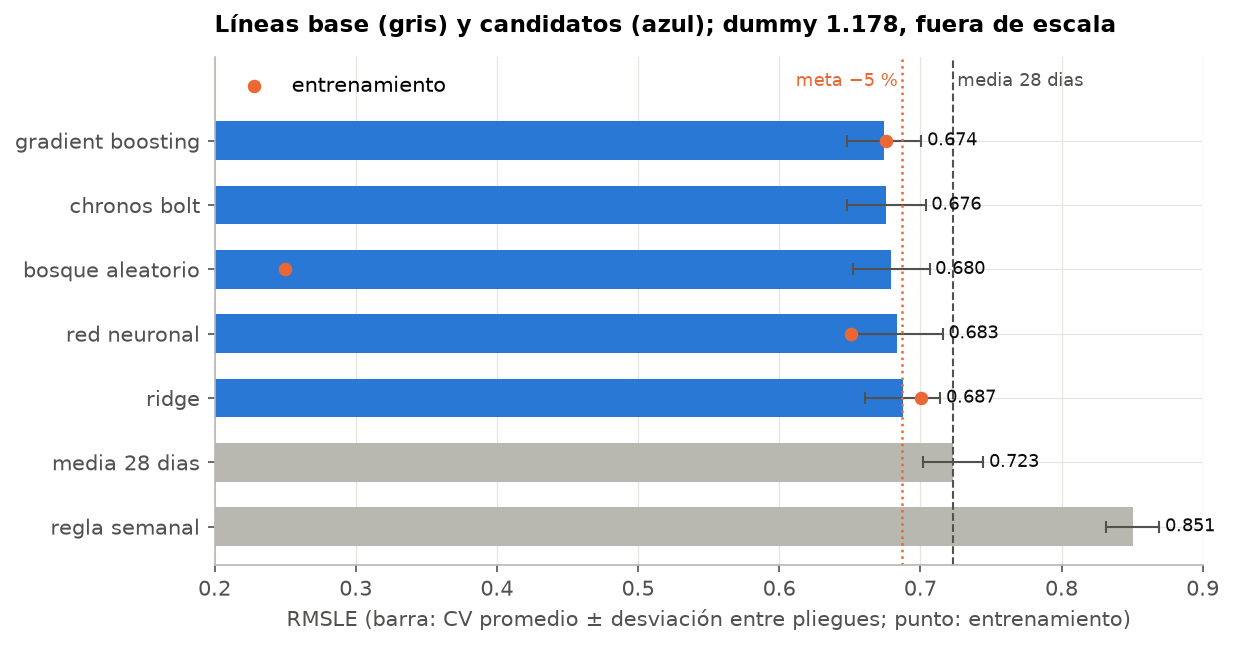

In [15]:
orden = tabla.drop(index='linea base').sort_values('rmsle_cv', ascending=False)
colores = [GRIS if f == 'baseline' else AZUL for f in orden['fase']]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
y_pos = np.arange(len(orden))
ax.barh(y_pos, orden['rmsle_cv'], xerr=orden['rmsle_cv_std'], color=colores, height=0.6,
        error_kw={'ecolor': TINTA_2, 'capsize': 3, 'linewidth': 1})
ax.scatter(orden['rmsle_entrenamiento'], y_pos, color=NARANJA, zorder=3, s=30, label='entrenamiento')
base = tabla.loc[mejor_base, 'rmsle_cv']
ax.axvline(base, color=TINTA_2, linestyle='--', linewidth=1)
ax.axvline(0.95 * base, color=NARANJA, linestyle=':', linewidth=1.2)
ax.set_ylim(-0.6, len(orden) + 0.3)  # una franja libre arriba para las etiquetas de las líneas
ax.text(base + 0.003, len(orden) - 0.15, mejor_base, fontsize=8.5, color=TINTA_2)
ax.text(0.95 * base - 0.003, len(orden) - 0.15, 'meta −5 %', fontsize=8.5, color=NARANJA, ha='right')
for y, (v, s) in enumerate(zip(orden['rmsle_cv'], orden['rmsle_cv_std'])):
    ax.text(v + s + 0.004, y, f'{v:.3f}', va='center', fontsize=8.5, color=TINTA)
ax.set_yticks(y_pos, orden.index)
ax.set_xlim(0.2, 0.9)
ax.set_xlabel('RMSLE (barra: CV promedio ± desviación entre pliegues; punto: entrenamiento)')
ax.set_title(f"Líneas base (gris) y candidatos (azul); dummy {tabla.loc['linea base', 'rmsle_cv']:.3f}, fuera de escala",
             pad=12)
ax.legend(loc='upper left', frameon=False)
fig.savefig(f'{FIGURAS}/candidatos_cv.png')
plt.show()

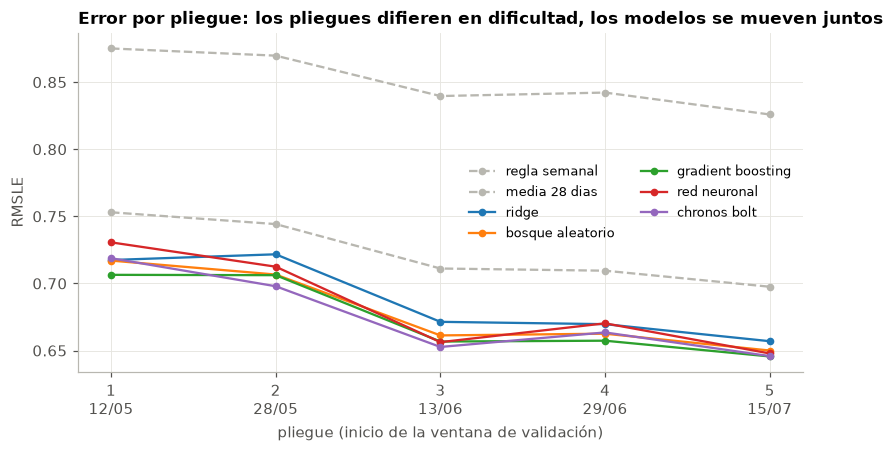

,linea base,regla semanal,media 28 dias,ridge,bosque aleatorio,gradient boosting,red neuronal,chronos bolt
pliegue,,,,,,,,
1,1.1802,0.8751,0.7530,0.7175,0.7170,0.7064,0.7306,0.7188
2,1.1869,0.8697,0.7442,0.7217,0.7066,0.7062,0.7125,0.6979
3,1.1802,0.8396,0.7111,0.6714,0.6613,0.6567,0.6563,0.6527
4,1.1762,0.8422,0.7095,0.6697,0.6626,0.6573,0.6703,0.6635
5,1.1680,0.8259,0.6975,0.6570,0.6500,0.6456,0.6478,0.6458


In [16]:
por_pliegue = pd.DataFrame({n: r['pliegues'] for n, r in resultados.items()},
                           index=pd.Index(range(1, len(esquema_temporal) + 1), name='pliegue'))
fig, ax = plt.subplots(figsize=(8.5, 4))
for nombre in por_pliegue.columns:
    es_base = resultados[nombre]['fase'] == 'baseline'
    if nombre == 'linea base':
        continue
    ax.plot(por_pliegue.index, por_pliegue[nombre], marker='o', markersize=4,
            color=GRIS if es_base else None, linestyle='--' if es_base else '-', label=nombre)
ax.set_xticks(por_pliegue.index, [f'{i}\n{d:%d/%m}' for i, d in zip(tabla_pliegues.index, tabla_pliegues['valida_desde'])])
ax.set_xlabel('pliegue (inicio de la ventana de validación)')
ax.set_ylabel('RMSLE')
ax.set_title('Error por pliegue: los pliegues difieren en dificultad, los modelos se mueven juntos')
ax.legend(frameon=False, fontsize=8.5, ncol=2)
fig.savefig(f'{FIGURAS}/candidatos_pliegues.png')
plt.show()
por_pliegue

**Comparación pareada.** Como todos los modelos se evalúan en los mismos pliegues y los pliegues
difieren en dificultad, la diferencia entre dos modelos se mide **pliegue a pliegue**. La pregunta
es si la mejora es consistente en los 5 pliegues y mayor que su propia variación.

In [17]:
referencia = por_pliegue[mejor_base]
pareada = pd.DataFrame({
    'mejora_media_%': 100 * (1 - por_pliegue.div(referencia, axis=0)).mean(),
    'mejora_std_%': 100 * (1 - por_pliegue.div(referencia, axis=0)).std(ddof=0),
    'pliegues_mejores': (por_pliegue.lt(referencia, axis=0)).sum(),
}).drop(index=['linea base', mejor_base]).sort_values('mejora_media_%', ascending=False)
pareada['supera_meta_5%'] = pareada['mejora_media_%'] >= 5
print(f'Mejora relativa frente a "{mejor_base}", pliegue a pliegue:')
pareada

Mejora relativa frente a "media 28 dias", pliegue a pliegue:


,mejora_media_%,mejora_std_%,pliegues_mejores,supera_meta_5%
gradient boosting,6.7503,0.9640,5,True
chronos bolt,6.5759,1.2385,5,True
bosque aleatorio,6.0531,0.9417,5,True
red neuronal,5.5217,1.7579,5,True
ridge,4.9530,1.0351,5,False
regla semanal,-17.6498,0.9533,0,False


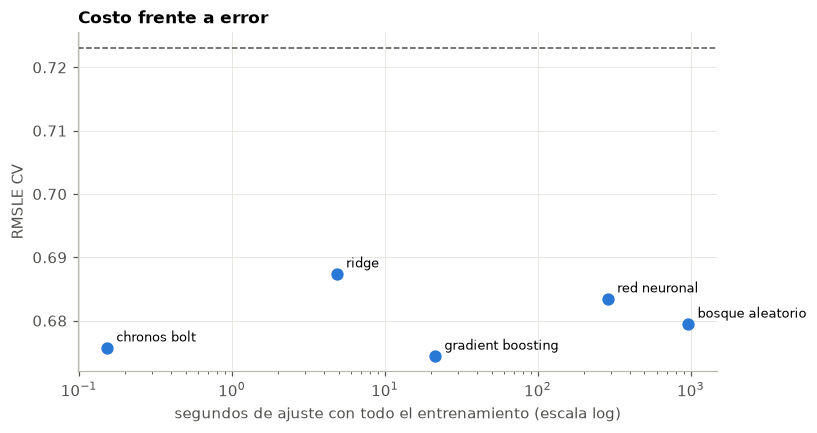

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 4))
candidatos = tabla[tabla['fase'] == 'candidato']
ax.scatter(candidatos['segundos'], candidatos['rmsle_cv'], s=50, color=AZUL, zorder=3)
for nombre, f in candidatos.iterrows():
    ax.annotate(nombre, (f['segundos'], f['rmsle_cv']), textcoords='offset points', xytext=(6, 4), fontsize=8.5)
ax.axhline(base, color=TINTA_2, linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_xlabel('segundos de ajuste con todo el entrenamiento (escala log)')
ax.set_ylabel('RMSLE CV')
ax.set_title('Costo frente a error')
fig.savefig(f'{FIGURAS}/candidatos_tiempo.png')
plt.show()

## 7. Diagnóstico y modelos que pasan al tuning

**Frente a las líneas base.** Los cinco candidatos superan a las tres líneas base en **los 5 pliegues**.
Cuatro alcanzan la meta del PSet 1 (≥ 5 % frente a la mejor línea base); Ridge queda en el límite (4,9 %).
La mejor línea base no es la regla semanal del PSet 1 sino la **media de 28 días**: una sola semana
es ruidosa en series intermitentes, y promediar la corrige. Es un hallazgo: la referencia que el negocio
usaría por intuición es 18 % peor que la media simple.

**Sobreajuste (entrenamiento frente a CV).**

| Modelo | Brecha | Diagnóstico |
|---|---|---|
| Bosque aleatorio | +0,43 | Memoriza (0,25 en entrenamiento). Árboles sin límite de profundidad, hojas de casi una fila. Generaliza bien solo porque promedia 100 árboles. |
| Red neuronal | +0,03 | Sobreajuste leve; la penalización `alpha` y el tamaño de la capa son las palancas. |
| Gradient boosting, Ridge | ≈ 0 o negativa | No sobreajustan: tienen poca capacidad (100 iteraciones, modelo lineal). Hay margen para modelos más complejos. |

La brecha negativa no es un error. El error de entrenamiento promedia toda la historia (incluye diciembre,
feriados y series que recién empiezan), que es más difícil de predecir que las semanas de mayo a julio
de la validación. El dummy, que no aprende nada, muestra el mismo efecto en sentido contrario de la escala.

**¿Las diferencias entre candidatos son reales?** Con la desviación entre pliegues (≈ 0,027) los cuatro primeros
son indistinguibles: los pliegues difieren en dificultad y todos los modelos se mueven juntos. La comparación
pareada es más fina (desviación de la mejora ≈ 1 %). Gradient boosting y Chronos empatan (6,8 % y 6,6 %); el bosque
(6,1 ± 0,9 %) y la red (5,5 ± 1,8 %) también se solapan entre sí.

**Costo.** Gradient boosting se ajusta en 21 s. Chronos no se ajusta (su costo está en la inferencia, ≈ 15 s por
pliegue). La red tarda 289 s y el bosque por defecto 968 s, con un modelo de ~4 GB. Ese costo del bosque viene de sus
valores por defecto (hojas de una fila), no del algoritmo: en una medición en el pliegue 5, un bosque regularizado
(`min_samples_leaf=20`, `max_features=0.3`, `max_samples=0.3`) tardó 60 s, tuvo 10.800 nodos por árbol en vez de
486.000 y validó un poco mejor (0,647 frente a 0,650). Así, el tuning del bosque cabe en este equipo.

**Decisión: pasan al tuning los 3 mejores por CV: gradient boosting, Chronos-Bolt y el bosque aleatorio.**

- La **red neuronal** (4.ª) queda fuera. Su diferencia con el bosque no supera la variación pareada, pero la regla
  es el ranking, y no hay un motivo de costo para saltarlo.
- **Bosque aleatorio:** el espacio de búsqueda explora árboles regularizados. Ataca a la vez la brecha de 0,43 y el costo.
- **Chronos** no se reentrena: su tuning ajusta hiperparámetros de inferencia (largo del contexto, tamaño del
  modelo, cuantil del pronóstico y escala de la entrada).

## 8. LLM por prompting

El enunciado pide probar un LLM mediante *prompting*. El problema **sí se puede plantear así**: se le da al modelo la
historia de ventas como texto y se le pide el pronóstico en JSON. Diseño:

- **Modelo:** ChatGPT, por la interfaz web (consulta manual: el prompt se pegó en el chat y la respuesta se guardó en `docs/llm/`).
  Un chat nuevo, sin archivos, sin búsqueda web y sin ejecutar código: se mide el LLM, no una herramienta.
- **Muestra:** 39 series estratificadas por familia (semilla 42), en el **pliegue 5** (historia hasta el 14/07,
  pronóstico del 15/07 al 30/07). Nunca se usa la prueba. Un chat no admite las 2.000 series ni los 5 pliegues.
- **Información:** las últimas 8 semanas de cada serie, el día de la semana y los feriados del horizonte. Es la misma
  ventana que usa la media de 28 días y menos historia de la que ve Chronos.
- **Reproducibilidad:** el prompt se genera aquí y se comprueba que es idéntico, carácter por carácter, al que se pegó
  en el chat (`docs/llm/prompt_llm.txt`). La respuesta se guarda sin editar (`docs/llm/respuesta_llm.json`). Los dos
  quedan como artefactos de la corrida en MLflow.
- **Comparación pareada:** en las mismas 624 filas se evalúan la media de 28 días, gradient boosting y Chronos,
  entrenados con el entrenamiento del pliegue 5.

In [19]:
import hashlib
import json
import re

from src.pipeline import rmsle

DIR_LLM = '../docs/llm'
N_SERIES_LLM = 40
ent_5, val_5 = esquema_temporal[-1]
CORTE_LLM = X_ent['DATE'].iloc[ent_5].max()
DIAS = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']

# Muestra estratificada y proporcional por familia (mínimo una serie por familia), semilla fija.
series_llm = (ventas[SERIE + ['FAMILY']].astype({'FAMILY': str}).drop_duplicates(SERIE)
              .sort_values(SERIE))
cuota = (series_llm['FAMILY'].value_counts(normalize=True) * N_SERIES_LLM).round().clip(lower=1).astype(int)
series_llm = pd.concat([g.sample(cuota[f], random_state=SEMILLA) for f, g in series_llm.groupby('FAMILY')])
series_llm = series_llm.sort_values(['FAMILY'] + SERIE).reset_index(drop=True)
series_llm.insert(0, 'id', [f'S{i:02d}' for i in range(1, len(series_llm) + 1)])

ventana = pd.date_range(CORTE_LLM - pd.Timedelta(days=55), CORTE_LLM)
horizonte_llm = pd.date_range(CORTE_LLM + pd.Timedelta(days=1), periods=HORIZONTE)
historia_llm = (ventas.assign(DATE=pd.to_datetime(ventas['DATE']))
                .pivot_table(index=SERIE, columns='DATE', values=OBJETIVO).reindex(columns=ventana))
feriados = (ventas.assign(DATE=pd.to_datetime(ventas['DATE'])).drop_duplicates('DATE')
            .set_index('DATE')['IS_HOLIDAY'].astype(bool))


def texto_valor(x):
    return '-' if pd.isna(x) else f'{x:g}'


lineas = [f"{s.id} ({s.FAMILY}): " + ' '.join(texto_valor(x) for x in historia_llm.loc[(s.STORE_NBR, s.ITEM_NBR)])
          for s in series_llm.itertuples()]
futuro = ', '.join(f"{d:%d/%m} ({DIAS[d.day_of_week]}{', feriado' if feriados.get(d, False) else ''})"
                   for d in horizonte_llm)
prompt = f"""Eres un analista de demanda de una cadena de supermercados en Ecuador. Debes pronosticar las ventas diarias, en unidades, de {len(series_llm)} productos perecederos, cada uno en una tienda.

DATOS. Para cada serie tienes las ventas de los últimos 56 días, del {ventana[0]:%d/%m/%Y} al {ventana[-1]:%d/%m/%Y}, en orden cronológico. Un 0 es un día sin venta y un "-" es un día sin dato (el producto aún no se vendía en la tienda).
Fechas:        {' '.join(f'{d:%d/%m}' for d in ventana)}
Día de semana: {' '.join(DIAS[d.day_of_week] for d in ventana)}

{chr(10).join(lineas)}

TAREA. Pronostica las ventas de los 16 días siguientes: {futuro}.
Ten en cuenta el nivel reciente de cada serie, el patrón por día de la semana, la tendencia y la frecuencia de días sin venta. El error se medirá con RMSLE (error cuadrático en escala logarítmica), así que equivocarse por el doble pesa igual en una serie pequeña que en una grande.

FORMATO. No escribas ni ejecutes código y no expliques nada. Responde únicamente con un objeto JSON válido, con una clave por serie y una lista de exactamente 16 números no negativos en el orden de los días, así:
{{"S01": [n1, n2, ..., n16], "S02": [...], ...}}
Incluye las {len(series_llm)} series, de S01 a S{len(series_llm):02d}."""

with open(f'{DIR_LLM}/prompt_llm.txt', encoding='utf-8') as archivo:
    prompt_enviado = archivo.read()
print(f'{len(series_llm)} series, corte {CORTE_LLM:%d/%m/%Y}, prompt de {len(prompt):,} caracteres')
print(series_llm['FAMILY'].value_counts().to_dict())
# El prompt que se pegó en el chat es exactamente el que genera este código.
comprobar(4, prompt == prompt_enviado
          and series_llm.equals(pd.read_csv(f'{DIR_LLM}/series_llm.csv').astype(series_llm.dtypes.to_dict())))
print(prompt[:900], '\n[...]')

39 series, corte 14/07/2017, prompt de 9,949 caracteres
{'PRODUCE': 12, 'DAIRY': 11, 'BREAD/BAKERY': 5, 'DELI': 4, 'MEATS': 2, 'POULTRY': 2, 'EGGS': 1, 'PREPARED FOODS': 1, 'SEAFOOD': 1}
Comprobación 4: OK
Eres un analista de demanda de una cadena de supermercados en Ecuador. Debes pronosticar las ventas diarias, en unidades, de 39 productos perecederos, cada uno en una tienda.

DATOS. Para cada serie tienes las ventas de los últimos 56 días, del 20/05/2017 al 14/07/2017, en orden cronológico. Un 0 es un día sin venta y un "-" es un día sin dato (el producto aún no se vendía en la tienda).
Fechas:        20/05 21/05 22/05 23/05 24/05 25/05 26/05 27/05 28/05 29/05 30/05 31/05 01/06 02/06 03/06 04/06 05/06 06/06 07/06 08/06 09/06 10/06 11/06 12/06 13/06 14/06 15/06 16/06 17/06 18/06 19/06 20/06 21/06 22/06 23/06 24/06 25/06 26/06 27/06 28/06 29/06 30/06 01/07 02/07 03/07 04/07 05/07 06/07 07/07 08/07 09/07 10/07 11/07 12/07 13/07 14/07
Día de semana: sáb dom lun mar mié jue vie sáb dom l

In [20]:
with open(f'{DIR_LLM}/respuesta_llm.json', encoding='utf-8') as archivo:
    texto = archivo.read()
respuesta = json.loads(re.sub(r'^```(?:json)?|```$', '', texto.strip(), flags=re.MULTILINE))
completa = (set(respuesta) == set(series_llm['id'])
            and all(len(v) == HORIZONTE and min(v) >= 0 for v in respuesta.values()))
comprobar(5, completa)

pred_llm = pd.DataFrame([(s.STORE_NBR, s.ITEM_NBR, d, float(respuesta[s.id][i]))
                         for s in series_llm.itertuples() for i, d in enumerate(horizonte_llm)],
                        columns=SERIE + ['DATE', 'llm por prompting'])
filas = (X_ent.iloc[val_5].reset_index().merge(pred_llm, on=SERIE + ['DATE']).set_index('index'))
X_llm, y_llm = X_ent.loc[filas.index], y_ent.loc[filas.index]

# Los demás modelos, entrenados con el entrenamiento del pliegue 5, sobre las mismas filas.
comparados = {
    'media 28 dias': Pipeline([('modelo', ReglaSemanal('media_28'))]),
    'gradient boosting': Pipeline([('preparar', preparacion()),
                                   ('modelo', en_escala_log(HistGradientBoostingRegressor(random_state=SEMILLA)))]),
    'chronos bolt': Pipeline([('modelo', ChronosBolt())]),
}
predicciones = filas[SERIE + ['DATE', 'llm por prompting']].assign(real=y_llm)
for nombre, modelo in comparados.items():
    modelo.fit(X_ent.iloc[ent_5], y_ent.iloc[ent_5])
    predicciones[nombre] = modelo.predict(X_llm)

MODELOS_LLM = ['llm por prompting', 'media 28 dias', 'gradient boosting', 'chronos bolt']
error_llm = pd.Series({m: rmsle(predicciones['real'], predicciones[m]) for m in MODELOS_LLM},
                      name='rmsle').sort_values()
por_serie = predicciones.groupby(SERIE).apply(
    lambda g: pd.Series({m: rmsle(g['real'], g[m]) for m in MODELOS_LLM}))
gana_llm = (por_serie['llm por prompting'] < por_serie['media 28 dias']).sum()
print(f'{len(predicciones)} filas ({predicciones[SERIE].drop_duplicates().shape[0]} series × {HORIZONTE} días)')
print(f'Series en que el LLM supera a la media de 28 días: {gana_llm} de {len(por_serie)}')
error_llm.to_frame().assign(
    mejora_vs_media_28_pct=lambda t: 100 * (1 - t['rmsle'] / t.loc['media 28 dias', 'rmsle']))

Comprobación 5: OK


624 filas (39 series × 16 días)
Series en que el LLM supera a la media de 28 días: 12 de 39


,rmsle,mejora_vs_media_28_pct
gradient boosting,0.5981,5.7187
chronos bolt,0.6072,4.2751
media 28 dias,0.6343,0.0000
llm por prompting,0.6622,-4.3905


In [21]:
with mlflow.start_run(run_name='llm por prompting') as corrida_llm:
    mlflow.set_tags({'fase': 'candidato', 'familia': 'llm por prompting', 'git_commit': GIT_COMMIT,
                     'git_cambios_sin_commit': GIT_SUCIO, 'modelo_guardado': 'no',
                     'nota': 'consulta manual en la interfaz web; prompt y respuesta guardados como artefactos'})
    mlflow.log_params({'servicio': 'ChatGPT (interfaz web)', 'modelo_llm': 'no especificado por la interfaz',
                       'fecha_consulta': '2026-11-16', 'herramientas': 'sin codigo ni busqueda web',
                       'n_series_llm': len(series_llm), 'pliegue': len(esquema_temporal),
                       'corte': f'{CORTE_LLM:%Y-%m-%d}', 'dias_historia': len(ventana),
                       'huella_prompt': hashlib.sha256(prompt.encode('utf-8')).hexdigest(),
                       'semilla': SEMILLA, **{k: v for k, v in DATOS.items() if k != 'filas_entrenamiento'}})
    mlflow.log_metrics({f"rmsle_muestra_{m.replace(' ', '_')}": v for m, v in error_llm.items()})
    mlflow.log_metrics({'mejora_vs_media_28_pct': 100 * (1 - error_llm['llm por prompting'] / error_llm['media 28 dias']),
                        'series_gana_vs_media_28': int(gana_llm), 'filas_evaluadas': len(predicciones)})
    for archivo in ['prompt_llm.txt', 'respuesta_llm.json', 'series_llm.csv']:
        mlflow.log_artifact(f'{DIR_LLM}/{archivo}', artifact_path='llm')
    mlflow.log_text(predicciones.to_csv(index=False), 'llm/predicciones_pliegue5.csv')
print('run_id:', corrida_llm.info.run_id)

🏃 View run llm por prompting at: http://127.0.0.1:5050/#/experiments/3/runs/ab1b0baab56b469b8c8bf0d8dc7bacbe
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
run_id: ab1b0baab56b469b8c8bf0d8dc7bacbe


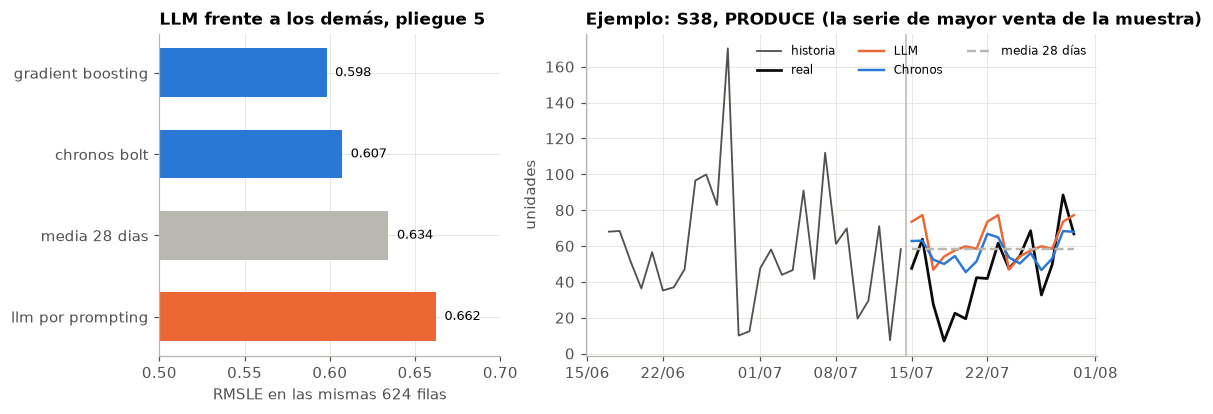

In [22]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.5]})
orden_llm = error_llm.sort_values(ascending=False)
izq.barh(orden_llm.index, orden_llm.values, height=0.6,
         color=[NARANJA if m == 'llm por prompting' else (GRIS if m == 'media 28 dias' else AZUL) for m in orden_llm.index])
for y, v in enumerate(orden_llm.values):
    izq.text(v + 0.005, y, f'{v:.3f}', va='center', fontsize=8.5)
izq.set_xlim(0.5, 0.7)
izq.set_xlabel('RMSLE en las mismas 624 filas')
izq.set_title('LLM frente a los demás, pliegue 5')

nivel = pd.Series({s.id: historia_llm.loc[(s.STORE_NBR, s.ITEM_NBR)].mean() for s in series_llm.itertuples()})
id_ejemplo = nivel.idxmax()
ejemplo = series_llm.set_index('id').loc[id_ejemplo]
clave = (ejemplo['STORE_NBR'], ejemplo['ITEM_NBR'])
historia = historia_llm.loc[clave].iloc[-28:]
serie = predicciones.set_index(SERIE).loc[clave].set_index('DATE')
der.plot(historia.index, historia.values, color=TINTA_2, linewidth=1.2, label='historia')
der.plot(serie.index, serie['real'], color=TINTA, linewidth=1.8, label='real')
der.plot(serie.index, serie['llm por prompting'], color=NARANJA, linewidth=1.6, label='LLM')
der.plot(serie.index, serie['chronos bolt'], color=AZUL, linewidth=1.6, label='Chronos')
der.plot(serie.index, serie['media 28 dias'], color=GRIS, linewidth=1.6, linestyle='--', label='media 28 días')
der.axvline(CORTE_LLM + pd.Timedelta(hours=12), color=GRIS, linewidth=1)
der.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
der.set_ylabel('unidades')
der.set_title(f"Ejemplo: {id_ejemplo}, {ejemplo['FAMILY']} (la serie de mayor venta de la muestra)")
der.legend(frameon=False, fontsize=8, ncol=3)
fig.savefig(f'{FIGURAS}/llm_comparacion.png')
plt.show()

**Lectura.**

- **El LLM no supera ni a la línea base.** Su RMSLE (0,662) es 4,4 % peor que el de la media de 28 días en las mismas filas,
  y solo le gana en 12 de 39 series. Gradient boosting y Chronos sí la superan (5,7 % y 4,3 %), en línea con lo que
  mostró la CV completa.
- **Por qué.** La respuesta repite un patrón semanal fijo en los 16 días: copia la estructura de la última semana, como la
  regla semanal, que ya era la peor referencia de negocio (§6). Además redondea a enteros en series pequeñas (una serie
  con ventas entre 0 y 2 queda en 1 todos los días), y en escala log ese redondeo pesa. El ejemplo muestra que el LLM
  sigue el día de la semana pero no anticipa la caída de la serie, igual que Chronos y la media.
- **Conclusión para el proyecto.** Un LLM de texto general no es la herramienta para pronosticar series numéricas: no
  estima la incertidumbre, no ve las 2.000 series ni los 5 pliegues, y cada consulta es manual. El *state of the art*
  que sí compite es un modelo fundacional **de series de tiempo** (Chronos), que pasa al tuning. El LLM no pasa.
- **Limitaciones.** Es una sola consulta, en un pliegue y 39 series: la diferencia es indicativa, no una estimación con
  intervalo. ChatGPT no informa la versión exacta del modelo. Los datos de Favorita son públicos (Kaggle, 2017), así
  que no se puede descartar que el LLM los haya visto al entrenarse; aun así no obtuvo ventaja.